Imports


In [60]:
import pandas as pd
import os
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns



In [61]:
df = pd.read_csv("../Datasets/mpii_human_pose.csv")

# df = df.drop(columns=["ID"])
# df.set_index('NAME', inplace=True)

df.head(5)


,ID,NAME,r ankle_X,r ankle_Y,r knee_X,r knee_Y,r hip_X,r hip_Y,l hip_X,l hip_Y,...,r shoulder_Y,l shoulder_X,l shoulder_Y,l elbow_X,l elbow_Y,l wrist_X,l wrist_Y,Scale,Activity,Category
0,1,015601864.jpg,620,394,616,269,573,185,647,188,...,167,692,185,693,240,688,313,3.021046,curling,sports
1,2,015599452.jpg,-1,-1,-1,-1,806,543,720,593,...,281,719,299,711,516,545,466,5.641276,curling,sports
2,3,005808361.jpg,804,711,816,510,908,438,1040,454,...,253,1067,253,1167,353,1142,478,4.718488,curling,sports
3,4,086617615.jpg,301,461,305,375,201,340,294,342,...,261,314,264,327,320,362,346,2.681349,curling,sports
4,5,060111501.jpg,980,322,896,318,865,248,943,226,...,147,923,123,995,163,961,223,3.806403,curling,sports


C:\Users\Utilizador\AppData\Local\Temp\ipykernel_21740\663214899.py:13: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.scatter(keypoints[i], keypoints[i+1], c='r', marker='x')


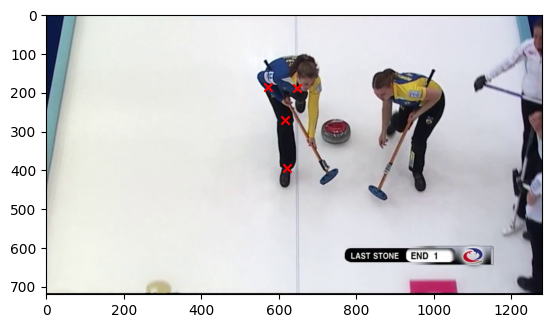

In [62]:
#3. Visualizing Keypoints
import matplotlib.pyplot as plt
import cv2
filtered_data = df[(df[['r ankle_X', 'r ankle_Y', 'r knee_X', 'r knee_Y']] != -1).all(axis=1)]

# Helper function to visualize keypoints
def visualize_keypoints(image_path, keypoints):
    img = cv2.imread(image_path)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    
    # Draw keypoints
    for i in range(0, len(keypoints), 2):
        plt.scatter(keypoints[i], keypoints[i+1], c='r', marker='x')
    plt.show()

# Example: Visualize keypoints for a random image in the subset
sample_image = df.iloc[0]['NAME']
sample_keypoints = df.iloc[0][['r ankle_X', 'r ankle_Y', 'r knee_X', 'r knee_Y', 'r hip_X', 'r hip_Y',
                                          'l hip_X', 'l hip_Y']]  # Select relevant keypoints
visualize_keypoints(f'../Datasets/images/{sample_image}', sample_keypoints)

Removing all rows with -1 for the sake of testing


In [63]:
df= df[(df[['r ankle_X', 'r ankle_Y', 'r knee_X', 'r knee_Y']] != -1).all(axis=1)]


In [64]:
df.describe()

,ID,r ankle_X,r ankle_Y,r knee_X,r knee_Y,r hip_X,r hip_Y,l hip_X,l hip_Y,l knee_X,...,r elbow_Y,r shoulder_X,r shoulder_Y,l shoulder_X,l shoulder_Y,l elbow_X,l elbow_Y,l wrist_X,l wrist_Y,Scale
count,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000,...,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000,11645.000000
mean,8790.647145,637.520052,580.446887,633.535595,488.828424,638.281838,401.635638,667.750107,401.967797,673.039931,...,339.043280,627.084843,272.356720,672.683212,271.413310,681.178617,340.281494,672.721511,370.627651,2.961253
std,5004.831689,329.853461,203.054926,313.365778,172.466651,322.863662,151.821016,327.452681,151.901235,322.858946,...,146.008089,317.688516,131.650725,324.246927,131.311897,326.377143,145.705339,322.774226,165.184222,1.492333
min,1.000000,1.000000,4.000000,7.000000,6.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,0.544118
25%,4355.000000,384.000000,422.000000,396.000000,354.000000,393.000000,288.000000,421.000000,288.000000,429.000000,...,233.000000,387.000000,177.000000,425.000000,177.000000,433.000000,234.000000,429.000000,251.000000,1.897367
50%,8825.000000,596.000000,566.000000,598.000000,473.000000,604.000000,380.000000,637.000000,381.000000,640.000000,...,317.000000,592.000000,248.000000,642.000000,248.000000,649.000000,318.000000,639.000000,348.000000,2.648278
75%,13078.000000,845.000000,700.000000,826.000000,595.000000,841.000000,497.000000,872.000000,498.000000,873.000000,...,422.000000,823.000000,343.000000,873.000000,342.000000,881.000000,423.000000,867.000000,468.000000,3.685778
max,17372.000000,1873.000000,1108.000000,1863.000000,1071.000000,1868.000000,1073.000000,1908.000000,1040.000000,1916.000000,...,1059.000000,1915.000000,1033.000000,1912.000000,956.000000,1921.000000,1034.000000,1908.000000,1067.000000,16.704500


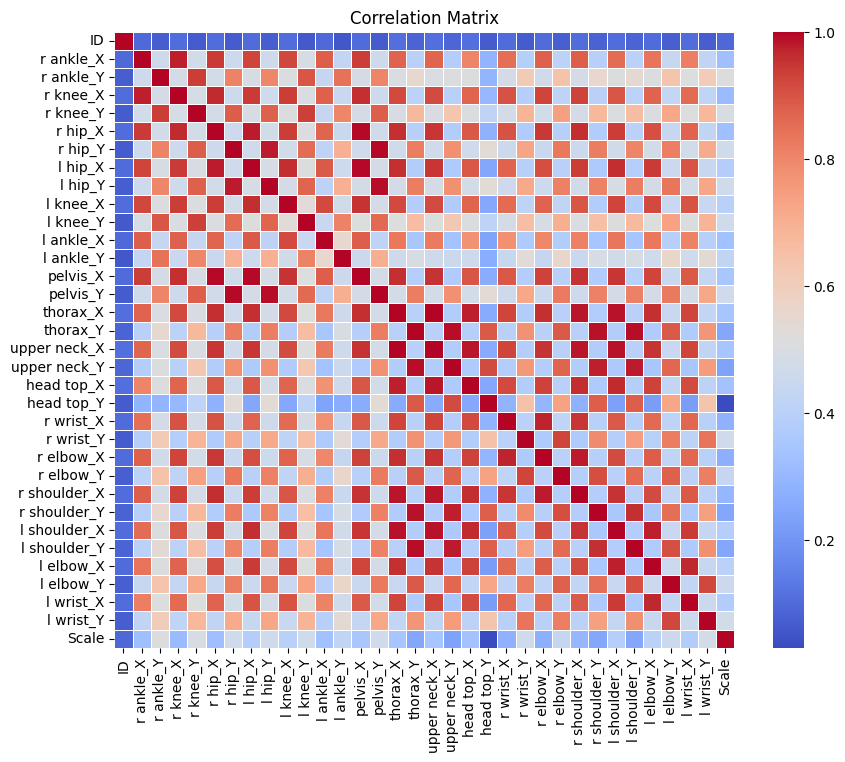

In [65]:

numeric_df = df.select_dtypes(include=['number'])
coor_matr = numeric_df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(coor_matr, annot=False, cmap='coolwarm', fmt='.2f', linewidth=0.5)
plt.title('Correlation Matrix')
plt.show()

In [66]:
count_neg_ones = df.apply(lambda col: (col == -1).sum())
count_neg_ones

ID                0
NAME              0
r ankle_X         0
r ankle_Y         0
r knee_X          0
r knee_Y          0
r hip_X          13
r hip_Y          13
l hip_X          12
l hip_Y          12
l knee_X         22
l knee_Y         22
l ankle_X       237
l ankle_Y       237
pelvis_X         22
pelvis_Y         22
thorax_X         33
thorax_Y         33
upper neck_X     33
upper neck_Y     33
head top_X       33
head top_Y       34
r wrist_X        59
r wrist_Y        59
r elbow_X        38
r elbow_Y        38
r shoulder_X     13
r shoulder_Y     13
l shoulder_X     23
l shoulder_Y     23
l elbow_X        36
l elbow_Y        36
l wrist_X        76
l wrist_Y        76
Scale             0
Activity          0
Category          0
dtype: int64

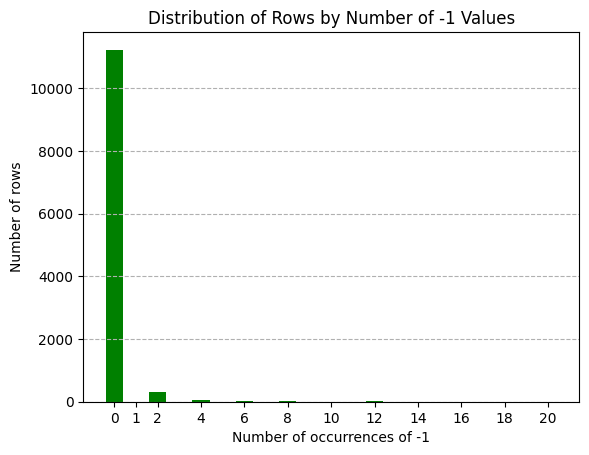

In [67]:
count_minus_one = (df == -1).sum(axis=1)
frequency = count_minus_one.value_counts().sort_index()
plt.bar(frequency.index, frequency.values, color='green')
plt.xlabel('Number of occurrences of -1')
plt.ylabel('Number of rows')
plt.title('Distribution of Rows by Number of -1 Values')
plt.xticks(frequency.index)
plt.grid(axis='y', linestyle='--', alpha=1)
plt.show()

Aqui em cima temos predominância de valores pares, indica que possivelmente são imagens em que não aparecem ambas as pernas, ou braços, etc


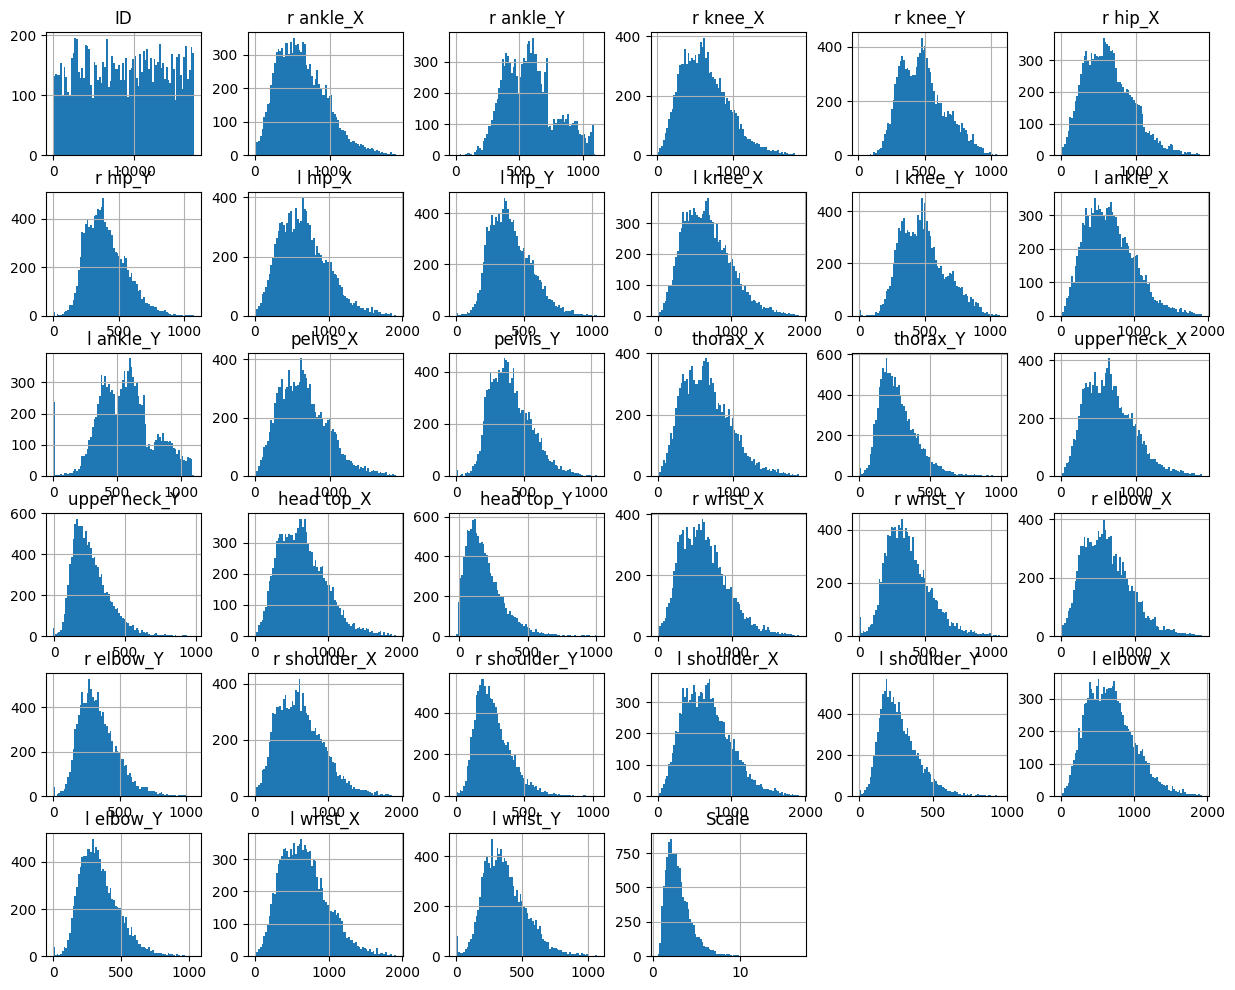

In [68]:
# histdf = df.drop(columns=["ID"])
df.hist(figsize=(15,12),bins = 80)
plt.title("Features Distribution")
plt.show()

In [69]:
# keypoint_columns = df.select_dtypes(include='number')
# keypoint_columns = keypoint_columns.drop(columns=["Scale"])
# # keypoint_columns = keypoint_columns.columns
# keypoint_columns.columns

In [70]:
subset = df

def plot_body_part(body_part):
	x_coords = [col for col in subset.columns if col.endswith(body_part + '_X')]
	y_coords = [col for col in subset.columns if col.endswith(body_part + '_Y')]

	plt.figure(figsize=(8, 6))

	# Plot each point and label it
	for x, y in zip(x_coords, y_coords):
		body_part = x[:-2]  # Remove '_X' suffix to get the body part
		plt.scatter(subset[x], subset[y], label=body_part)
		plt.text(subset[x].iloc[0], subset[y].iloc[0] + 20, body_part, fontsize=9, ha='center')

	# Set axis limits to match 1920x1080 resolution
	plt.xlim(0, 1920)
	plt.ylim(0, 1080)

	# Add plot details
	plt.title("Body Part Coordinates (1920x1080)")
	plt.xlabel("X Coordinate")
	plt.ylabel("Y Coordinate")
	plt.axhline(0, color='black', linewidth=0.1, linestyle='--')
	plt.axvline(0, color='black', linewidth=0.1, linestyle='--')
	plt.grid(True)
	plt.legend(loc='upper right', fontsize=8)

	# Show the plot
	plt.show()
 


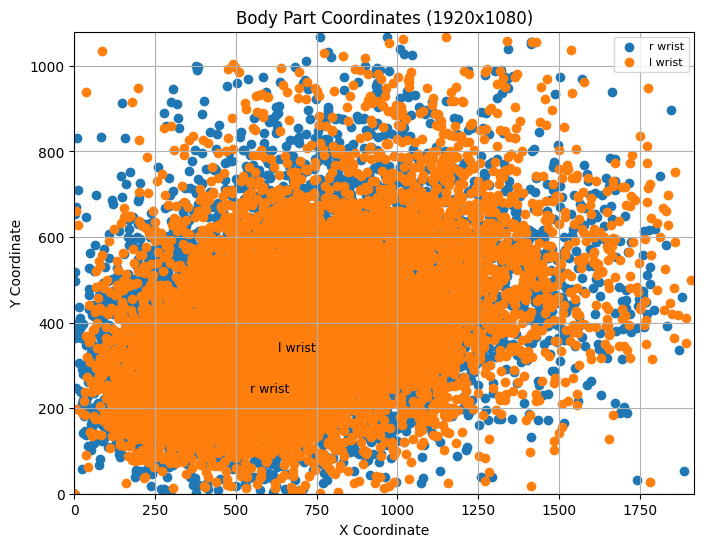

In [71]:
plot_body_part('wrist')

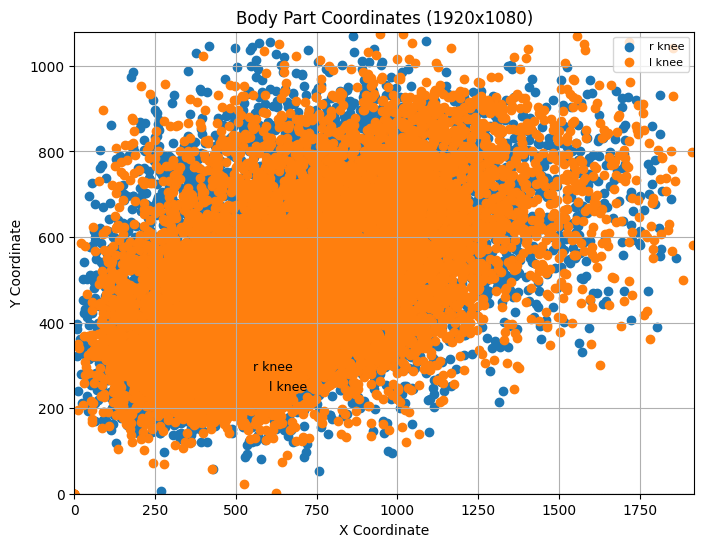

In [72]:
plot_body_part('knee')

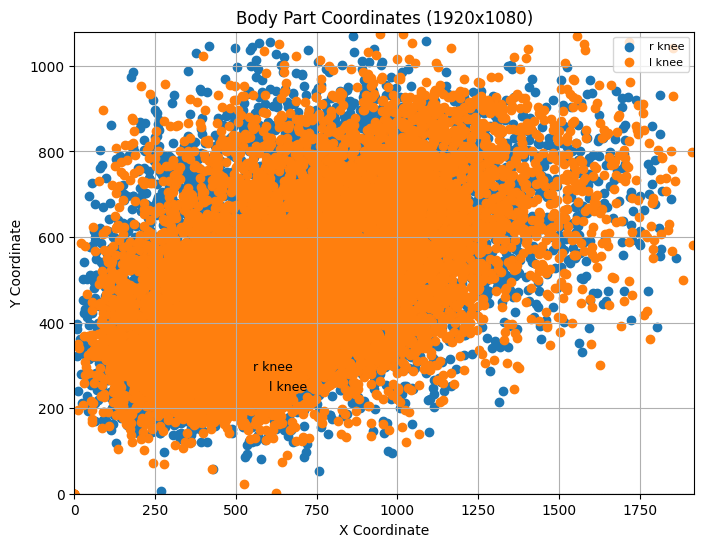

In [73]:
plot_body_part('knee')

In [74]:
df["Category"].unique()

array(['sports', 'inactivity quiet/light', 'miscellaneous', 'occupation',
       'water activities', 'home activities', 'lawn and garden',
       'religious activities', 'winter activities',
       'conditioning exercise', 'bicycling', 'dancing',
       'fishing and hunting', 'walking', 'running', 'home repair',
       'self care', 'music playing', 'transportation',
       'volunteer activities', '[]'], dtype=object)

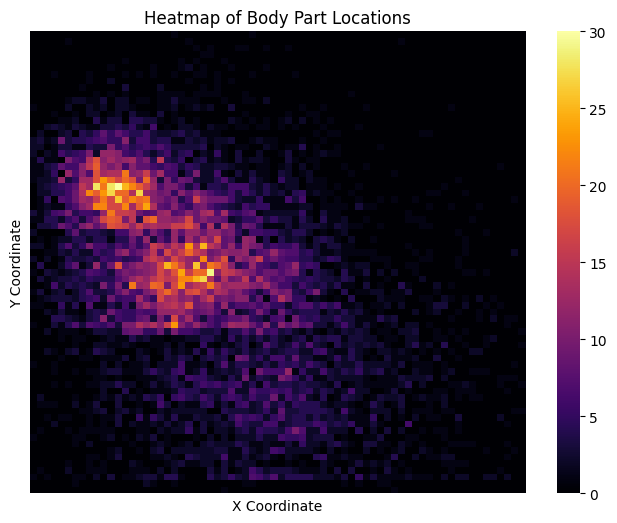

In [75]:
x = df["r ankle_X"]
y = df["r ankle_Y"]

heatmap_data, x_edges, y_edges = np.histogram2d(x, y, bins=(70, 70))


# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(heatmap_data.T, cmap="inferno", 
            xticklabels=False, yticklabels=False)
plt.title("Heatmap of Body Part Locations")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.show()

In [76]:
df.columns

Index(['ID', 'NAME', 'r ankle_X', 'r ankle_Y', 'r knee_X', 'r knee_Y',
       'r hip_X', 'r hip_Y', 'l hip_X', 'l hip_Y', 'l knee_X', 'l knee_Y',
       'l ankle_X', 'l ankle_Y', 'pelvis_X', 'pelvis_Y', 'thorax_X',
       'thorax_Y', 'upper neck_X', 'upper neck_Y', 'head top_X', 'head top_Y',
       'r wrist_X', 'r wrist_Y', 'r elbow_X', 'r elbow_Y', 'r shoulder_X',
       'r shoulder_Y', 'l shoulder_X', 'l shoulder_Y', 'l elbow_X',
       'l elbow_Y', 'l wrist_X', 'l wrist_Y', 'Scale', 'Activity', 'Category'],
      dtype='object')

Biggest Scale Images
 

<img src="../Datasets/Images/068162750.jpg" alt="title" width="300">  
<img src="../Datasets/Images/038440893.jpg" alt="title" width="300">  
<img src="../Datasets/Images/089881109.jpg" alt="title" width="300">  



Smallest Scale Images

<img src="../Datasets/Images/059907151.jpg" alt="title" width="300">  
<img src="../Datasets/Images/028418430.jpg" alt="title" width="300">  
<img src="../Datasets/Images/058219875.jpg" alt="title" width="300">  

In [79]:
df[["NAME", "Scale"]].sort_values(by="Scale", ascending=True).head(10)

,NAME,Scale
13981,059907151.jpg,0.544118
3329,028418430.jpg,0.600000
1574,058219875.jpg,0.600000
13975,013590738.jpg,0.614700
12960,054577715.jpg,0.633618
2745,039768441.jpg,0.679247
1889,098114373.jpg,0.679671
3195,030246632.jpg,0.686417
13974,003286273.jpg,0.697653
1079,041102847.jpg,0.715989
